# Telco Customer Churn Predictions


## EDA
#### Load DataSet

In [103]:
import pandas as pd
Customer=pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(Customer.info())
data=Customer.drop(columns=["Churn"])
target=Customer["Churn"]
data


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6


#### Identifying numerical and categorical features


In [104]:
from sklearn.compose import make_column_selector as Selector
numerical_columns=Selector(dtype_exclude=object)(data)
categorical_columns=Selector(dtype_include=object)(data)
numerical_columns , categorical_columns

(['SeniorCitizen', 'tenure', 'MonthlyCharges'],
 ['customerID',
  'gender',
  'Partner',
  'Dependents',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod',
  'TotalCharges'])

#### Inspecting values for missing values and duplicates
##### Missing values

In [105]:
(data.isnull().sum() , target.isnull().sum())

(customerID          0
 gender              0
 SeniorCitizen       0
 Partner             0
 Dependents          0
 tenure              0
 PhoneService        0
 MultipleLines       0
 InternetService     0
 OnlineSecurity      0
 OnlineBackup        0
 DeviceProtection    0
 TechSupport         0
 StreamingTV         0
 StreamingMovies     0
 Contract            0
 PaperlessBilling    0
 PaymentMethod       0
 MonthlyCharges      0
 TotalCharges        0
 dtype: int64,
 np.int64(0))

When inspecting missing value pandas search for null markers but if we have a empty string it will not be considered as empty there for we must inspect our rows string values

In [106]:
Empty=data[categorical_columns].apply(lambda col : col.astype(str).str.strip().eq("") ).sum()
print(Empty)

customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
dtype: int64


In [107]:
Empty=data[categorical_columns].apply(lambda col : col.astype(str).str.strip().eq("") ).any(axis=1)
data[Empty]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,


as we can see we have 11 values in total charge which are empty in a important  feature of our study because as we can see for all the rows the contract is a one year at minimum which means that the sum of all the total charges of these rwos will affect the wights of the toatal charge feature while training 

##### Total charges feature
we have two problems with the value of total charges column 

it is a numerical value but pandas has read it as str which is due to the empty values in the column who forces pandas to consider it as a text

empty values considred as empty strings which must be imputed with a meaningfull value

In [108]:
data["TotalCharges"]=pd.to_numeric(data["TotalCharges"].astype(str).str.strip() , errors="coerce")
print(data["TotalCharges"].dtype)


float64


as we can observe tenure value which means for how long the client was a client for the company is 0 for all empty Total charges

lets inspect our dataset if there is rows with tenure value = 0 and have a valid total charges

In [115]:
data[data["tenure"] == 0 ]['TotalCharges'].notnull()

488     False
753     False
936     False
1082    False
1340    False
3331    False
3826    False
4380    False
5218    False
6670    False
6754    False
Name: TotalCharges, dtype: bool

as we can see all the values with tenure 0 have a an empty Total Charges value 

teh most meaningfull value would be 0 to replace this non valid values but the imputation should be in the training set to prevent data leackage

##### Duplicates

In [109]:
data.duplicated(keep=False).sum()

np.int64(0)

#### Target distribution

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

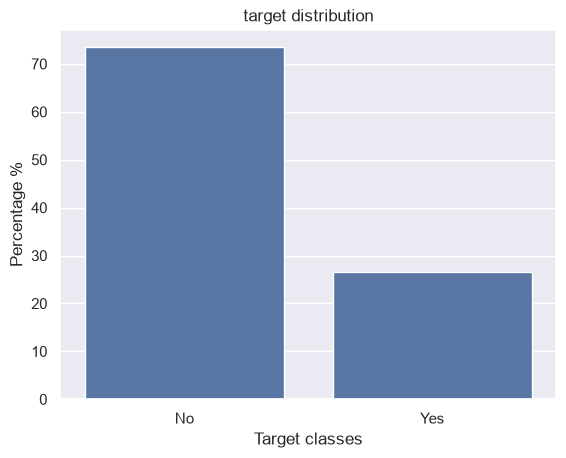

In [110]:
targetDistribution=target.value_counts(normalize=True)*100
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.set()

sns.barplot(x=targetDistribution.index , y=targetDistribution.values ,fill=True )
plt.xlabel("Target classes")
plt.ylabel("Percentage %")
plt.title("target distribution")
targetDistribution


#### Observations
most  of our features are categorical

we have an imbalanced Dataset with  74 for for negative churn and 26 for postive values of churn



## Prepreocessing

## Model Training

## Model Evaluation